## Лабораторная работа №1 | Вариант 5

Выполнила: Ротова Дарья Максимовна, М8О-313БВ-24.

### 1. Numpy

In [2]:
import numpy as np

1. Создайте единичную матрицу размером 3х3

In [3]:
E = np.eye(3)
print(E)

[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


2. Создайте кастомный dtype который описывает цвет состоящий из 4х unsigned bytes(RGBA пиксель)

In [4]:
my_color = np.dtype([
    ('R', np.uint8),
    ('G', np.uint8),
    ('B', np.uint8),
    ('A', np.uint8),
])

In [5]:
# пример использования
red = np.array([(255, 0, 0, 255)], dtype=my_color)
print(red)
print(red['A'])


[(255, 0, 0, 255)]
[255]


3. Как игнорировать все numpy warnings(не рекомендуем к использованию)?

In [6]:
np.seterr(all='ignore') 
a = np.array([1, 2, 3, 4])
print(a / 0)

[inf inf inf inf]


4. Создайте случайный вектор размера 10 и отсортируйте его

In [7]:
vect = np.random.randint(0, 200, size=10)
print("Неотсортированный:", vect)
sorted_vect = np.sort(vect)
print("Отсортированный:  ", sorted_vect)


Неотсортированный: [156  54 106 123  63 170 137 198 125  53]
Отсортированный:   [ 53  54  63 106 123 125 137 156 170 198]


5. Создайте read-only массив(неизменяемый)

In [8]:
read_arr = np.array([1, 2, 3])
read_arr.flags.writeable = False
print(read_arr)
read_arr[1] = 5 # это вызовет ошибку

[1 2 3]


ValueError: assignment destination is read-only

6. Рассмотрим случайную матрицу размером 10х2, представляющую декартовы координаты, преобразуем их в полярные координаты

In [10]:
coords = np.random.uniform(-20, 20, (10, 2))
x = coords[:, 0]
y = coords[:, 1]
r = np.hypot(x, y)
angle = np.arctan2(y, x)
polar = np.column_stack([r, angle])
print("Декартовы:\n", coords)
print("Полярные:\n", polar)

Декартовы:
 [[ 17.45115458  19.37051835]
 [ -9.04482785   8.66125613]
 [-19.3474793  -12.61228019]
 [-14.36907367   4.52162642]
 [ -6.42862869  -6.28741075]
 [ 14.62602216  19.69445401]
 [-16.09254478  11.61053623]
 [-19.6586622   17.05876209]
 [ 11.30072665   6.97235728]
 [  1.48455769  14.46418183]]
Полярные:
 [[26.07220316  0.83747695]
 [12.52302953  2.37785437]
 [23.09533647 -2.56389531]
 [15.06371082  2.8367251 ]
 [ 8.99215218 -2.36729953]
 [24.53145008  0.93201794]
 [19.8437534   2.51659202]
 [26.02814561  2.42688485]
 [13.27856125  0.55281357]
 [14.54016738  1.46851764]]


7. Создайте структурированный массив с координатами x и y, охватывающий область [0,1]x[0,1]

In [13]:
coords = np.dtype([
    ('x', np.float64),
    ('y', np.float64)
])
a = np.zeros(5, dtype=coords)
points = np.random.uniform(0, 1, (5, 2))
a['x'] = points[:, 0]
a['y'] = points[:, 1]
print(a)

[(0.35904981, 0.28869696) (0.8971876 , 0.04052474)
 (0.55686804, 0.16868222) (0.38633219, 0.42506182)
 (0.5466727 , 0.62131383)]


8. Учитывая два массива X и Y, постройте матрицу Коши $C$ ($C_{ij} =\frac{1}{x_i - y_j}$)

In [15]:
x = np.random.normal(size=(5))
y = np.random.normal(size=(5))
arr = 1.0 / (x[:, None] - y[None, :])
print(arr)

[[ -0.53474697   2.6239155   -0.41406683  -0.50932868  -1.50030614]
 [-16.31482983   0.45665036  -1.6492949   -6.46749624   0.87548904]
 [ -0.96586958   0.82249242  -0.63276632  -0.88600494   5.94614411]
 [ -0.65791419   1.36761847  -0.484266    -0.61985502  -3.16013295]
 [ -6.6644992    0.47594019  -1.43869457  -4.10889904   0.94924943]]


9. Как конвертировать массив float(32 bit) к массиву целых чисел (integer 32 bit) in place?

In [16]:
a = np.array([1.1, 2.6, 3.4, 9.7], dtype=np.float32)
print(a, a.dtype)
a_int = a.view(np.int32)
a_int[:] = a
a = a_int
print(a, a.dtype)

[1.1 2.6 3.4 9.7] float32
[1 2 3 9] int32


10. Как случайно заменить p элементов в 2D массиве?

In [17]:
arr = np.zeros((5, 5), dtype=int)
p = 10
replace = np.random.choice(arr.size, p, replace=False)
arr.ravel()[replace] = 2
print(arr)

[[0 2 2 2 2]
 [0 0 2 0 0]
 [2 2 0 2 0]
 [0 0 2 0 0]
 [2 0 0 0 0]]


### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Классический начальный набор данных - данные пассажиров титаника.

Файл: `data.csv`

```
PassangerId - уникальный номер пассажира
Survived - выжил человек или нет
Pclass - класс обслуживания
Name - имя человека, обращение к ней/нему
Sex - пол человека
Age - возраст на момент крушения
SibSp - количество братьев и сестер / супругов на борту "Титаника"
Parch - количество родителей / детей на борту "Титаника"
Ticket - номер билета
Fare - стоимость проезда для пассажиров
Cabin - каюта
Embarked - причал отбытия. C = Cherbourg Q = Queenstown S = Southampton
```

In [18]:
import pandas as pd

In [19]:
df = pd.read_csv('data.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


1. Узнайте сколько было на борту человек

In [20]:
print("Количество человек на борту:", len(df))

Количество человек на борту: 891


2. Какой медианный и средний возраста пассажиров

In [21]:
median_age = df['Age'].median().round(4)
mean_age = df['Age'].mean().round(4)
print(f"Медианный возраст - {median_age}, средний возраст - {mean_age}")

Медианный возраст - 28.0, средний возраст - 29.6991


3. Посчитайте процент выживаемости детей(до 16 лет) и взрослых

In [22]:
children = df[df['Age'] < 16]['Survived'].mean() * 100
adult = df[df['Age'] >= 16]['Survived'].mean() * 100
print(f'Процент выживших детей - {children:.4f}%. Процент выживших взрослых - {adult:.4f}%')

Процент выживших детей - 59.0361%. Процент выживших взрослых - 38.1933%


4. Верна ли гипотеза, что женщины и дети сажались в шлюпки первыми и выживали больше?

In [59]:
mask_wch = (df['Sex'] == 'female') | (df['Age'] < 16) # женщины и дети до 16
mask_m = (df['Sex'] == 'male') & (df['Age'] >= 16) # мужчины старше 16 лет
woman_or_children = df[mask_wch]
men = df[mask_m]
survive_w_or_ch = woman_or_children['Survived'].mean() * 100
survive_men = men['Survived'].mean() * 100

print(f'Процент выживших детей и женщин - {survive_w_or_ch:.4f}%')
print(f'Процент выживших мужчин - {survive_men:.4f}%')
if survive_w_or_ch > survive_men:
    print('Гипотеза верна.')
else:
    print('Гипотеза опровергнута.')

Процент выживших детей и женщин - 71.7514%
Процент выживших мужчин - 17.4334%
Гипотеза верна.


Гипотеза верна, поскольку процент выживших женщин и детей превышает процент выживших мужчин. Из этого можно сделать вывод, что в шлюпки первыми сажались женщины и дети.

5. Зависит ли выживаемость от класса обслуживания?

In [24]:
survive_class = df.groupby('Pclass')['Survived'].mean() * 100
print('Процент выживаемости по классам:', survive_class)

Процент выживаемости по классам: Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


Да, выживаемость зависит от класса обслуживания: чем более высокий класс, тем более высокий процент выживаемости.

6. Посчитайте средний возраст умерших женщин и мужчин

In [25]:
dead = df[df['Survived'] == 0]
mean_age_dead = dead.groupby('Sex')['Age'].mean()
print('Средний возраст умерших женщин и мужчин:', mean_age_dead)

Средний возраст умерших женщин и мужчин: Sex
female    25.046875
male      31.618056
Name: Age, dtype: float64


7. Различается ли процент выживаемости пассажиров с хотя бы одним родственником на борту и одиночек?

In [26]:
mask_alone = (df['SibSp'] == 0) & (df['Parch'] == 0)
alone = df[mask_alone]['Survived'].mean() * 100
mask_not_alone = (df['SibSp'] > 0) | (df['Parch'] > 0)
not_alone = df[mask_not_alone]['Survived'].mean() * 100
print(f'Процент выживших одиночек - {alone:.2f}%, процент выживших пассажиров с родственниками - {not_alone:.2f}%')

Процент выживших одиночек - 30.35%, процент выживших пассажиров с родственниками - 50.56%


Процент выживаемости пассажиров с родственниками выше, чем процент выжимаемости пассажиров-одиночек.

8. Различается ли средняя стоимость билета у умерших и выживших пассажиров?

In [27]:
mean_cost = df.groupby('Survived')['Fare'].mean()
print(f"Средняя стоимость билета у умерших пассажиров: {mean_cost[0]:.4f}")
print(f"Средняя стоимость билета у выживших пассажиров: {mean_cost[1]:.4f}")

Средняя стоимость билета у умерших пассажиров: 22.1179
Средняя стоимость билета у выживших пассажиров: 48.3954


Средняя стоимость билета у выживших пассажиров выше, чем у умерших.

9. Выведите максимальный и минимальный возраст выживших пассажиров во 2 классе обслуживания

In [28]:
df_new = df[(df['Survived'] == 1) & (df['Pclass'] == 2)]
max_age = df_new['Age'].max()
min_age = df_new['Age'].min()
print(f'Максимальный возраст - {max_age}, минимальный возраст - {min_age}')

Максимальный возраст - 62.0, минимальный возраст - 0.67


10. Подтвердите или опровергните гипотезу: молодым мужчинам(от 18 лет) выжить легче, чем более взрослым

In [29]:
man = df[(df['Sex'] == 'male') & (df['Age'] >= 18)]
young_man = man[man['Age'] <= 35]
adult_man = man[man['Age'] > 35]
survive_young = young_man['Survived'].mean() * 100
survive_adult = adult_man['Survived'].mean() * 100
print(f'Процент выживаемости молодых мужчин (от 18 до 35 вкл.) - {survive_young:.2f}')
print(f'Процент выживаемости взрослых мужчин (от 35 и старше) - {survive_adult:.2f}\n')
if survive_young > survive_adult:
    print('Гипотеза верна: молодым мужчинам выжить было легче, чем более взрослым.')
else:
    print('Гипотеза опровергнута: проценты выживших молодых и взрослых мужчин очень близки.')

Процент выживаемости молодых мужчин (от 18 до 35 вкл.) - 17.53
Процент выживаемости взрослых мужчин (от 35 и старше) - 18.06

Гипотеза опровергнута: проценты выживших молодых и взрослых мужчин очень близки.


### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

1. Постройте гистограмму распределения возрастов пассажиров

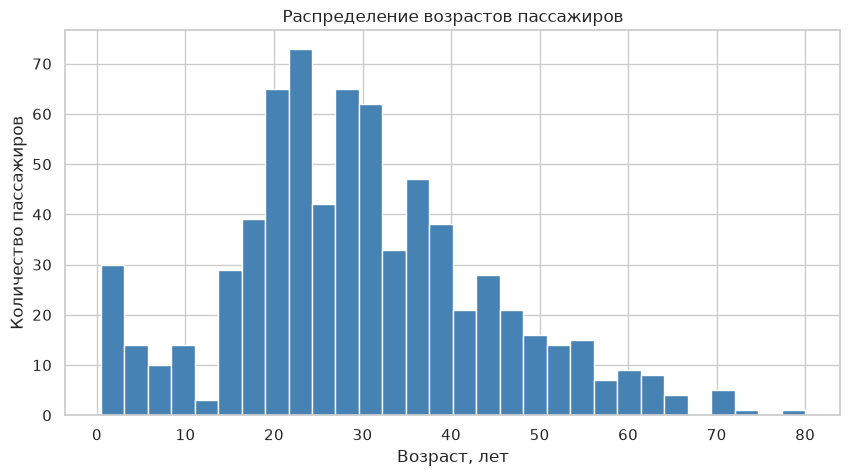

In [31]:
age_data = df['Age'].dropna()
sns.set_theme(style='whitegrid')
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(age_data, bins=30, color='steelblue', edgecolor='white')
ax.set(title='Распределение возрастов пассажиров', xlabel='Возраст, лет', ylabel='Количество пассажиров')
plt.show()

2. Постройте гистограммы распределения цен для пассажиров разных классов

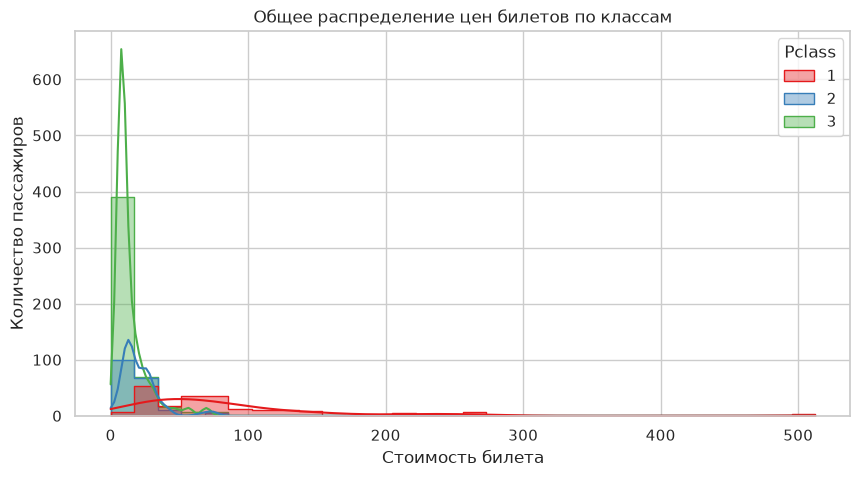

In [32]:
sns.set_theme(style='whitegrid')
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=df, x='Fare', hue='Pclass', palette='Set1', bins=30, kde=True, element='step', alpha=0.4, ax=ax)
ax.set(title='Общее распределение цен билетов по классам', xlabel='Стоимость билета', ylabel='Количество пассажиров')
plt.show()

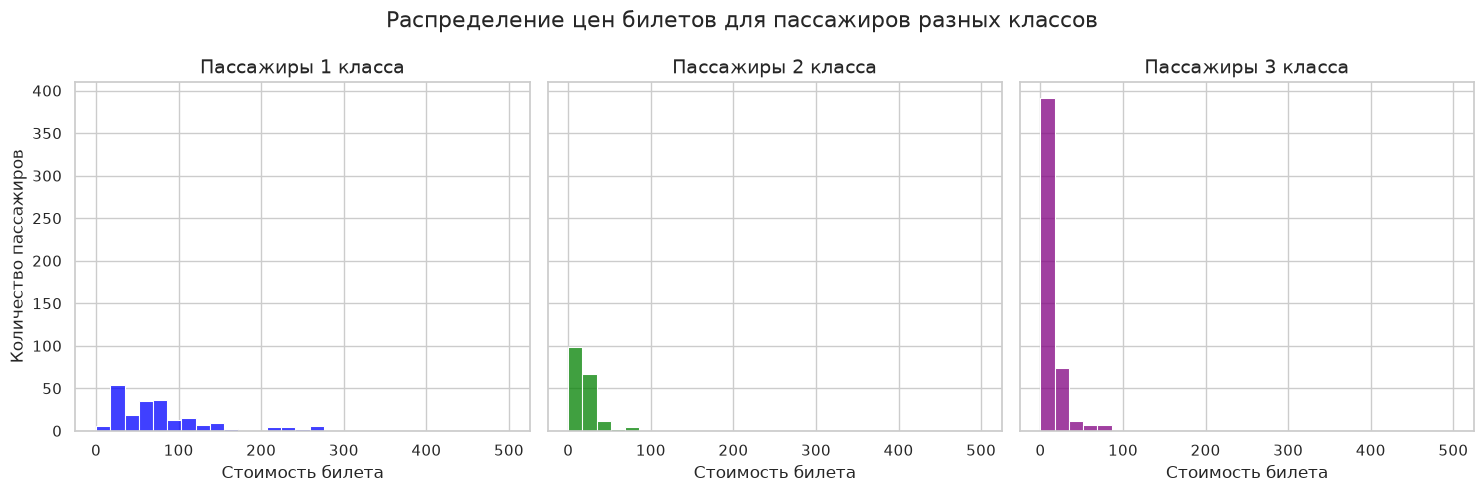

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
new_bins = np.linspace(0, 500, 30)
colors = ['blue', 'green', 'purple']
for i, pclass in enumerate([1, 2, 3]):
    class_data = df[df['Pclass'] == pclass]
    sns.histplot(data=class_data, x='Fare', bins=new_bins, ax=axes[i], color=colors[i])
    axes[i].set_title(f'Пассажиры {pclass} класса', fontsize=14)
    axes[i].set_xlabel('Стоимость билета')
    axes[i].set_ylabel('Количество пассажиров')

fig.suptitle('Распределение цен билетов для пассажиров разных классов', fontsize=16)
plt.tight_layout()
plt.show()

3. Постройте зависимость цены от возраста пассажира

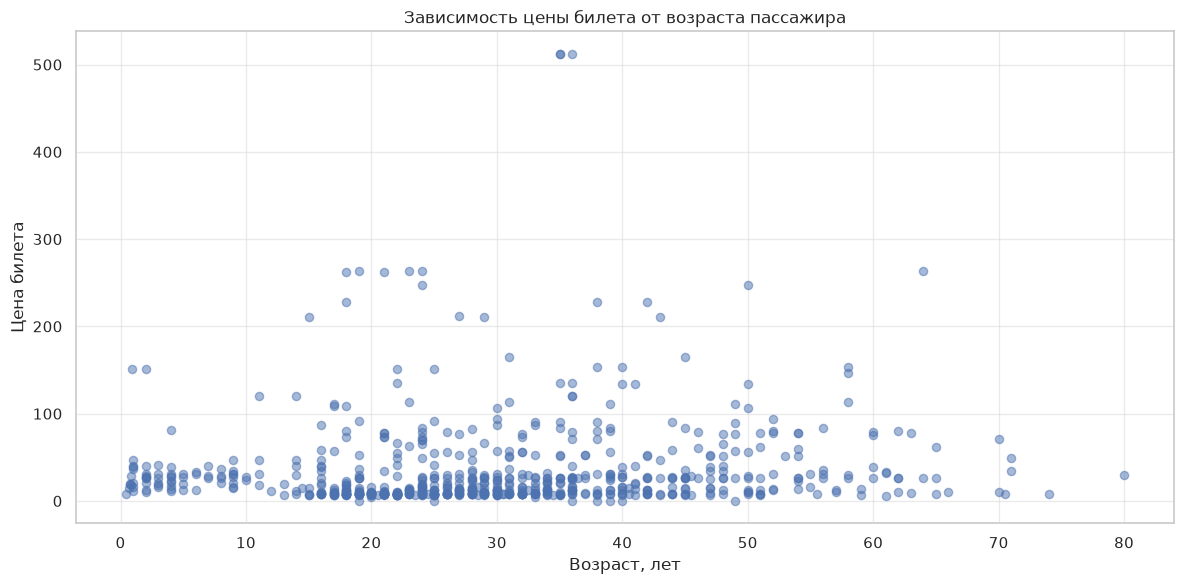

In [34]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(df['Age'], df['Fare'], alpha=0.5, s=35)
ax.set(title='Зависимость цены билета от возраста пассажира', xlabel='Возраст, лет', ylabel='Цена билета')
ax.grid(alpha=0.4)
plt.tight_layout()
plt.show()

4. Постройте box plot отображающий распределение цен на билеты в разных классах

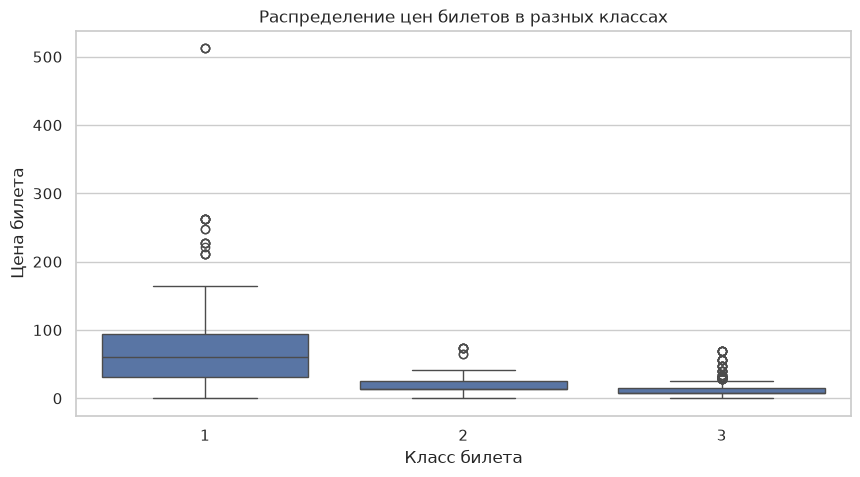

In [36]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df, x='Pclass', y='Fare', ax=ax)
ax.set(title='Распределение цен билетов в разных классах', xlabel='Класс билета', ylabel='Цена билета')
plt.show()

5. Визуализируйте распределение долей выживших среди мужчин, женщин и детей(до 16 лет)

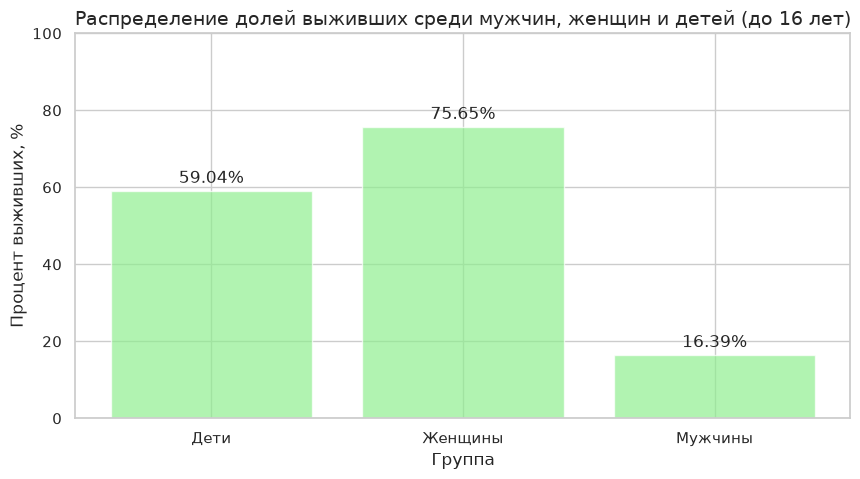

In [37]:
fig, ax = plt.subplots(figsize=(10, 5))
df['Group'] = np.where(df['Age'] < 16, 'Дети', np.where(df['Sex'] == 'male', 'Мужчины', 'Женщины'))
survive_procents = df.groupby('Group')['Survived'].mean() * 100
br = ax.bar(survive_procents.index, survive_procents.values, color='lightgreen', alpha=0.7)
ax.bar_label(br, fmt='%.2f%%', padding=3)
ax.set_ylim(0, 100)
ax.set_title('Распределение долей выживших среди мужчин, женщин и детей (до 16 лет)', fontsize=14)
ax.set_xlabel('Группа', fontsize=12)
ax.set_ylabel('Процент выживших, %', fontsize=12)
plt.show()

6. Сравните плотности распределения возрастов выживших и умерших пассажиров, сделайте выводы

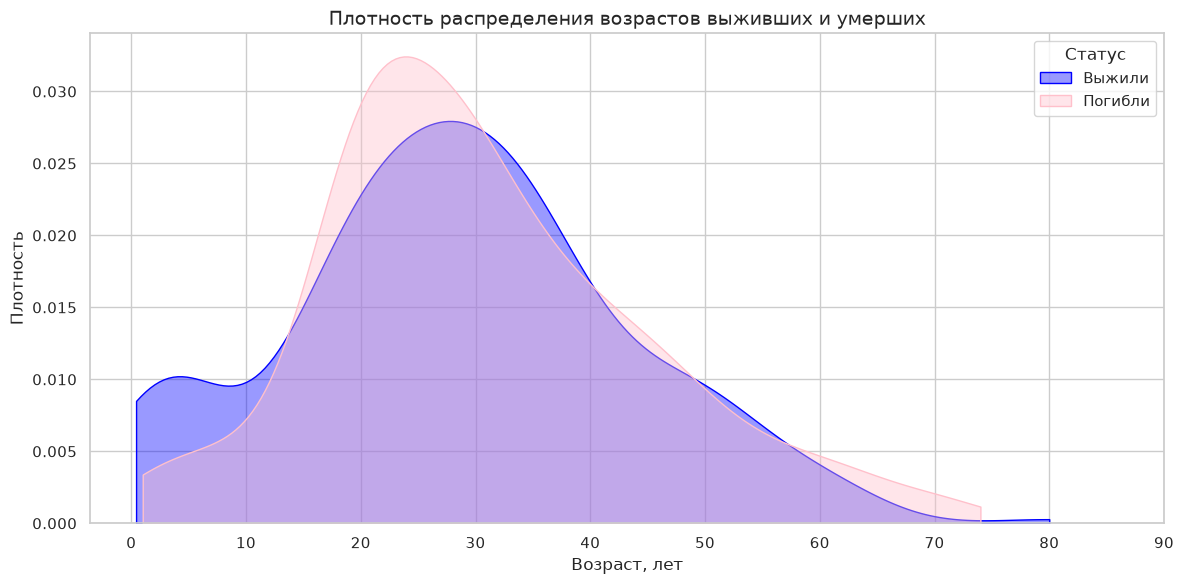

In [69]:
fig, ax = plt.subplots(figsize=(12, 6))
df_age = df.dropna(subset=['Age']).copy()
df_age['Status'] = df_age['Survived'].map({0: 'Погибли', 1: 'Выжили'})

sns.kdeplot(data=df_age, x='Age', hue='Status', fill=True, common_norm=False, cut=0,
            palette={'Выжили': 'blue', 'Погибли': 'pink'}, alpha=0.4, ax=ax)

ax.set_title('Плотность распределения возрастов выживших и умерших', fontsize=14)
ax.set_xlabel('Возраст, лет', fontsize=12)
ax.set_ylabel('Плотность', fontsize=12)
ax.set_xticks(np.arange(0, 91, 10))
ax.legend(title='Статус', labels=['Выжили', 'Погибли'])
plt.tight_layout()
plt.show()

**Выводы**:  
График плотности показывает, насколько возраст влиял на выживание в этой ситуации. 
По синей линии, означающей выживших, заметно виден пик выживаемости у детей до 12 лет примерно. 
Большая часть погибших приходится на возраст 20-35 лет, что видно по розовой линии.
Также больше погибло, чем выжило, пожилых людей в возрасте от 60 лет и старше, так как им физически было сложнее спастись.
График подтверждает, что приоритет отдавался детям и женщинам при спасении.



7. Постройте круговую диаграмму отображающую выживаемость мужчин и женщин в разных классах обслуживания(визуализация должна быть интуитивно понятная без объяснений, женщины и мужчины соответствующих классов объеденены визуально в одну группу и 2 подгруппы)*

\* Задание на доп. балл

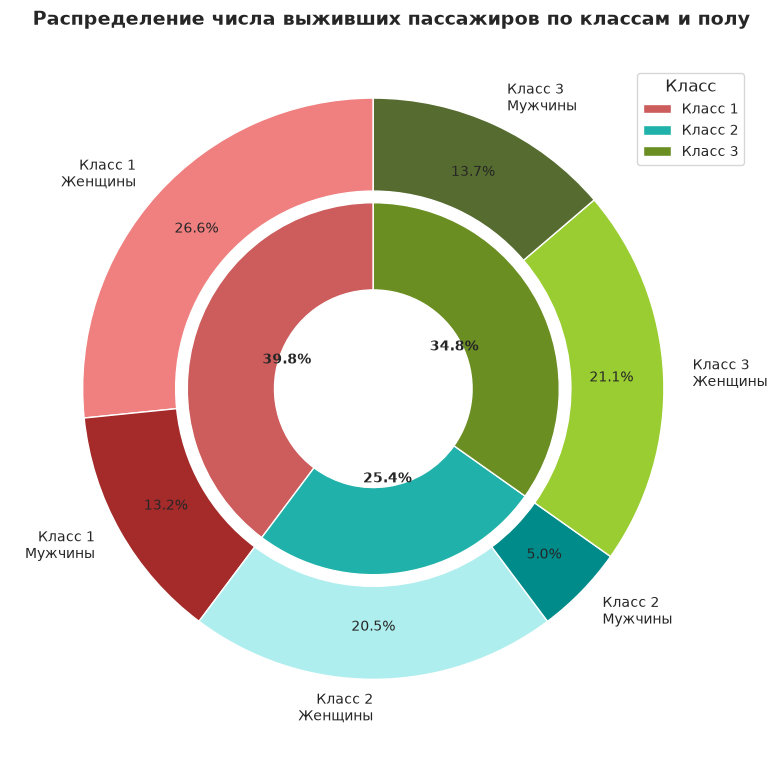

In [54]:
class_group = df.groupby('Pclass')['Survived'].sum()
class_sex_group = df.groupby(['Pclass', 'Sex'])['Survived'].sum()

in_order = class_group.tolist()
out_order = class_sex_group.tolist()

in_colors = ['indianred', 'lightseagreen', 'olivedrab']
out_colors = ['lightcoral', 'brown', 'paleturquoise', 'darkcyan', 'yellowgreen', 'darkolivegreen']

in_labels = ['Класс 1', 'Класс 2', 'Класс 3']
out_labels = [
    'Класс 1\nЖенщины', 'Класс 1\nМужчины',
    'Класс 2\nЖенщины', 'Класс 2\nМужчины',
    'Класс 3\nЖенщины', 'Класс 3\nМужчины',
]

fig, ax = plt.subplots(figsize=(8, 8))

outer_wedges, outer_texts, outer_autotexts = ax.pie(
    out_order,
    colors=out_colors,
    labels=out_labels,
    wedgeprops={'width': 0.32, 'edgecolor': 'w'},
    startangle=90,
    autopct='%1.1f%%',
    pctdistance=0.82,
    textprops={'fontsize': 10},
)

inner_wedges, inner_texts, inner_autotexts = ax.pie(
    in_order,
    radius=0.64,
    colors=in_colors,
    wedgeprops={'width': 0.30, 'edgecolor': 'w'},
    startangle=90,
    autopct='%1.1f%%',
    pctdistance=0.49,
    textprops={'fontsize': 10, 'fontweight': 'bold'},
)

fig.suptitle('Распределение числа выживших пассажиров по классам и полу', fontsize=14, fontweight='bold', x=0.5, y=0.95)
fig.legend(inner_wedges, in_labels, title='Класс', loc='upper right', bbox_to_anchor=(0.95, 0.88), fontsize=10)
plt.tight_layout()
plt.show()


Описание:  
Вложенная круговая показывает структуру числа выживших, где внешний круг — женщины/мужчины каждого класса, внутренний круг — классы в сумме.